# TP1 — Cadrage BI, processus métier et découverte des sources

#

## 1. Contexte de l'entreprise 

Dans le cadre du développement de son activité numérique, une entreprise de vente en ligne souhaite exploiter les informations issues de ses transactions afin de mieux suivre ses performances commerciales. Elle dispose d'un historique de ventes provenant du dataset UCI Online Retail, mais les besoins d'analyse et les données disponibles n'ont pas encore été organisés dans une démarche BI structurée.

Le rôle du junior BI analyst est donc de comprendre les attentes de l'entreprise, de définir les principaux axes d'analyse, de décrire le déroulement du processus commercial et de vérifier si les données existantes peuvent répondre aux besoins exprimés.

## 2. Données disponibles et outils utilisés

La source retenue pour cette étude est le fichier data.csv, extrait du dataset UCI Online Retail. Il contient des informations relatives aux factures, aux articles vendus, aux dates de transaction, aux prix, aux quantités et aux pays.

L'exploration sera effectuée avec Python et la bibliothèque Pandas, qui facilitent la lecture du fichier, l'inspection des colonnes et l'examen des principales caractéristiques des données. Matplotlib sera utilisé pour produire des représentations graphiques.

À ce stade du TP, l'utilisation d'une plateforme de visualisation ou d'un outil ETL, comme Power BI, Tableau, Pentaho ou Talend, n'est pas nécessaire.

Les champs attendus dans la source sont les suivants :

**InvoiceNo** : référence de la facture.

**StockCode** : référence attribuée à l'article.

**Description** : intitulé de l'article.

**Quantity** : nombre d'unités enregistré sur la ligne.

**InvoiceDate** : date et heure de l'opération.

**UnitPrice** : prix unitaire indiqué.

**CustomerID** : référence du client, lorsqu'elle est disponible.

**Country** : pays associé à la transaction.

## 3. Comment allez-vous raisonner ?

### Que devons-nous comprendre ou décider ?

L'objectif est d'analyser les performances commerciales, de repérer les produits les plus vendus, de comparer les pays et d'évaluer la disponibilité des informations clients.

### Quelles questions peut-on étudier avec les données ?

Le fichier permet d'étudier l'évolution temporelle des ventes, les quantités par produit, la répartition géographique des transactions et la présence des identifiants clients.

### Quel processus métier peut-on observer ?

Le processus étudié est la vente en ligne. Les données décrivent les factures, les produits, les dates, les pays et, lorsque l'information est disponible, les clients.

### Quelles variables sont nécessaires ?

Les champs InvoiceDate, Quantity et UnitPrice servent à analyser les ventes. StockCode et Description identifient les produits, Country permet les comparaisons géographiques, et InvoiceNo ainsi que CustomerID facilitent l'étude des factures et des informations clients.

In [ ]:
Quelles sont les limites de la source ?

In [ ]:
Le dataset ne contient que huit colonnes et ne fournit pas les coûts, les marges, les stocks ou les moyens de paiement. Des valeurs manquantes et des quantités négatives peuvent également influencer les analyses.

In [ ]:
Comment vérifier les données disponibles ?

In [ ]:
Python et Pandas permettront d'examiner les dimensions du fichier, les colonnes, les types de données et les valeurs manquantes, puis de comparer les résultats aux huit champs attendus.

## 3. Manipulation technique

### Comment importer le fichier et examiner son contenu ?

La première opération consiste à lire le fichier CSV et à vérifier sa structure générale. Le nombre de lignes et de colonnes donne une première indication sur le volume de données disponible. L'affichage des premières observations permet ensuite de contrôler les noms des variables et la présentation des enregistrements.

In [3]:
import pandas as pd
df = pd.read_csv("data.csv", encoding="cp1252")

print("Taille du dataset :", df.shape)
print("Liste des variables :", df.columns.tolist())
print("\nAperçu des premières lignes :")
print(df.head())

Taille du dataset : (541909, 8)
Liste des variables : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Aperçu des premières lignes :
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


### Comment évaluer la qualité initiale des données ?

Avant de répondre aux besoins métier, il est utile d'examiner le format des variables, les champs incomplets et les statistiques descriptives. Cette vérification préliminaire aide à repérer les difficultés susceptibles d'influencer les futures analyses.

In [4]:
# Informations générales sur les colonnes
df.info()

# Nombre de valeurs absentes pour chaque variable
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

# Résumé statistique des variables disponibles
print("\nRésumé descriptif :")
print(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Valeurs manquantes par colonne :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Résumé descriptif :
       InvoiceNo StockCode                         Description       Quantity  \
count     541909    541909                              540455  541909.0

Ces résultats permettent notamment de repérer les colonnes contenant des valeurs manquantes et de vérifier les types de données. Ils constituent un premier diagnostic de la source, sans effectuer à ce stade de nettoyage ou de transformation approfondie.

### Schéma du processus de vente

Le dataset permet de décrire plusieurs informations liées à une transaction commerciale :

**Référence de la facture** : InvoiceNo

**Référence et nom de l'article** : StockCode, Description

**Moment de la transaction** : InvoiceDate

**Localisation géographique** : Country

**Identification du client** : CustomerID

Ce schéma met en évidence les principales informations disponibles pour caractériser les opérations commerciales enregistrées dans la source.

### Quelle différence existe-t-il entre la référence de la facture et celle de l'article ?

InvoiceNo désigne la référence de facture associée à une opération commerciale, tandis que StockCode correspond à la référence de l'article. La variable Description complète cette information en indiquant le nom ou le libellé du produit. L'utilisation conjointe de ces champs permet d'examiner les articles présents dans les différentes factures.

## 4. Questions décisionnelles

### Question 1 : Comment évoluent les ventes dans le temps ?

L'entreprise souhaite savoir comment son activité varie d'une période à l'autre. L'analyse temporelle permet de repérer les périodes de progression, de recul ou de variation de l'activité commerciale.

Les variables mobilisées sont InvoiceDate, Quantity, UnitPrice et InvoiceNo. La date sert à répartir les opérations dans le temps. La quantité et le prix unitaire permettent de calculer un montant estimé par ligne, tandis que la référence de facture aide à examiner les transactions.

#### Graphe : évolution mensuelle du montant estimé des ventes

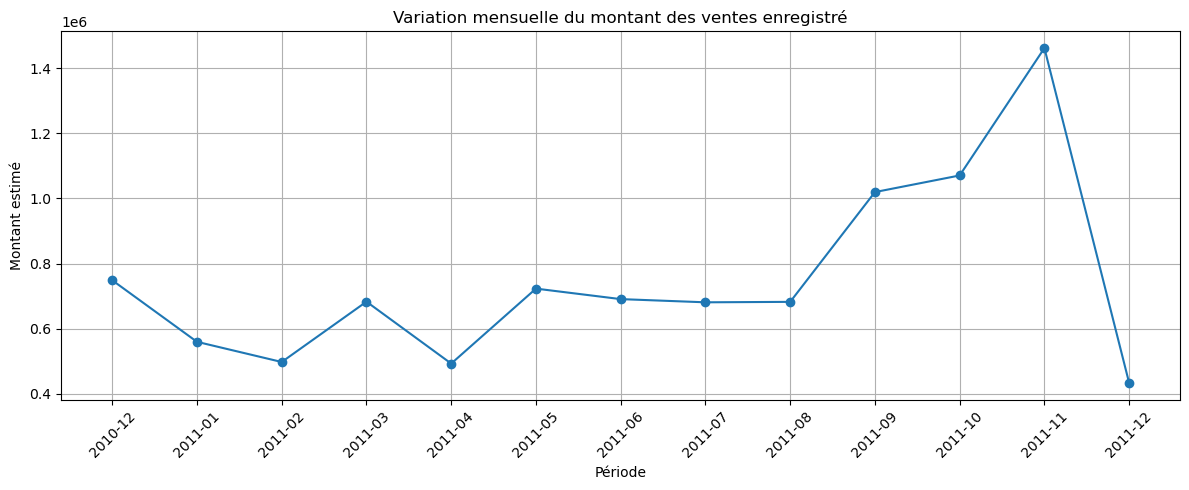

In [5]:
import matplotlib.pyplot as plt

# Préparer les variables utilisées dans le calcul
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Estimer le montant de chaque ligne
df["SalesAmount"] = df["Quantity"] * df["UnitPrice"]

# Conserver les lignes disposant d'une date exploitable
donnees_datees = df.dropna(subset=["InvoiceDate"]).copy()

# Calculer le montant cumulé pour chaque mois
ventes_mensuelles = donnees_datees.groupby(
    donnees_datees["InvoiceDate"].dt.to_period("M")
)["SalesAmount"].sum()

# Représenter les résultats
ventes_mensuelles.index = ventes_mensuelles.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(
    ventes_mensuelles.index,
    ventes_mensuelles.values,
    marker="o"
)
plt.title("Variation mensuelle du montant des ventes enregistré")
plt.xlabel("Période")
plt.ylabel("Montant estimé")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

#### Interprétation du graphique

La courbe permet de comparer le montant total enregistré au cours des différents mois. Les points les plus élevés indiquent les périodes où le montant cumulé est supérieur (**2011-11**), tandis que les points les plus bas correspondent aux périodes où il est plus faible(**2011-12**).

L'observation de la courbe permet ainsi de localiser les principales fluctuations de l'activité. Pour expliquer ces variations, il faudrait toutefois examiner les transactions correspondantes et tenir compte des éventuelles annulations et des retours.

### Question 2 : Quels sont les produits les plus vendus ?

L'objectif est de déterminer les références d'articles qui présentent les quantités cumulées les plus importantes dans l'historique. Ce classement permet de distinguer les produits les plus représentés en volume dans les enregistrements commerciaux.

Les champs nécessaires sont StockCode, Description, Quantity et UnitPrice. Le code et la description permettent de reconnaître les articles, tandis que la quantité sert à calculer leur volume cumulé. Le prix unitaire apporte une information complémentaire sur leur valeur commerciale.

#### Graphe : classement des dix produits selon les quantités enregistrées

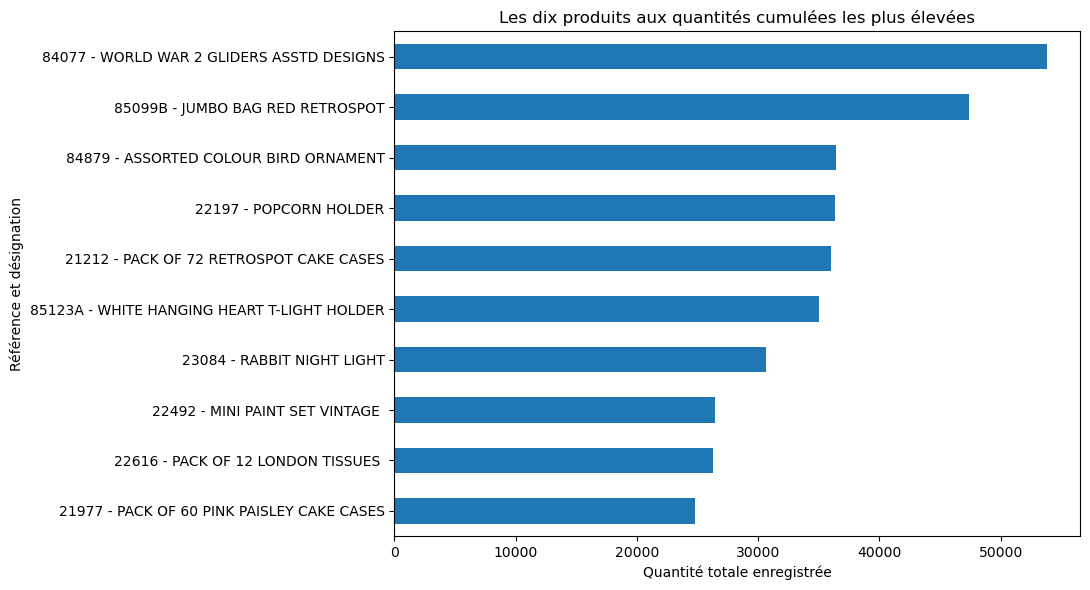

In [6]:
# Écarter les lignes dépourvues de référence ou de description
donnees_produits = df.dropna(
    subset=["StockCode", "Description"]
).copy()

# Calculer les quantités cumulées par référence et description
classement_produits = (
    donnees_produits
    .groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .nlargest(10)
)

# Préparer les libellés pour l'affichage
classement_produits.index = [
    f"{code} - {description}"
    for code, description in classement_produits.index
]

# Afficher le classement
classement_produits.sort_values().plot(
    kind="barh",
    figsize=(11, 6)
)

plt.title("Les dix produits aux quantités cumulées les plus élevées")
plt.xlabel("Quantité totale enregistrée")
plt.ylabel("Référence et désignation")
plt.tight_layout()
plt.show()

#### Interprétation du graphique

Le classement met en évidence les dix références présentant les quantités cumulées les plus élevées selon les données disponibles. Les articles situés en haut du classement initial sont ceux dont les volumes enregistrés sont les plus importants ca pour $World$ $War$ $2$ $Gliders$ $Asstd$ $Designs$ $et$ $Jumbo$ $Bag$ $Red$ $Retrospot$.

Il faut néanmoins distinguer les quantités enregistrées des quantités effectivement vendues nettes. Les retours ou les opérations d'annulation peuvent entraîner des valeurs négatives et modifier le classement obtenu.

## Question 3 : Quels pays contribuent le plus à l'activité commerciale ?

Cette question vise à comparer les résultats enregistrés selon les pays. Une telle analyse permet de repérer les marchés qui représentent les montants cumulés les plus importants dans le dataset.

Les variables utilisées sont Country, Quantity, UnitPrice et InvoiceNo. Le pays permet de regrouper les opérations par zone géographique. Les quantités et les prix servent à estimer les montants associés aux lignes de transaction, et la référence de facture peut être utilisée pour compléter l'analyse par un décompte des factures.

#### Graphe : classement des dix pays par montant estimé des ventes

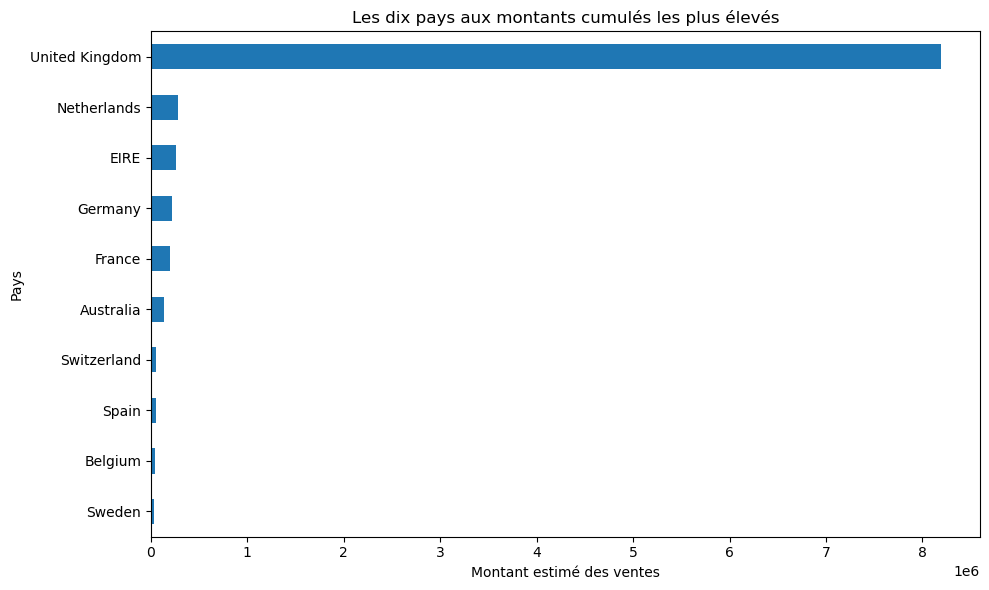

In [7]:
# Regrouper les montants par pays
classement_pays = (
    df.dropna(subset=["Country"])
    .groupby("Country")["SalesAmount"]
    .sum()
    .nlargest(10)
)

# Représenter les dix premiers pays
classement_pays.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Les dix pays aux montants cumulés les plus élevés")
plt.xlabel("Montant estimé des ventes")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

#### Interprétation du graphique

Ce graphique permet de comparer les montants estimés associés aux différents pays et d'identifier ceux qui occupent les premières positions du classement dans notre cas c'est **UK**. Il donne une première vision de la répartition géographique de l'activité enregistrée.


### Question 4 : Comment examiner les commandes et les clients identifiés ou inconnus ?

L'entreprise souhaite évaluer la disponibilité des informations d'identification des clients dans son historique transactionnel. L'analyse consiste à mesurer la part des lignes pour lesquelles une référence client est renseignée et celle des lignes où cette information est absente.

Les champs utilisés sont InvoiceNo, CustomerID et InvoiceDate. Ils permettent d'examiner les factures, de situer les transactions dans le temps et de vérifier la présence des identifiants clients.

#### Graphe : répartition des lignes selon la présence d'un identifiant client

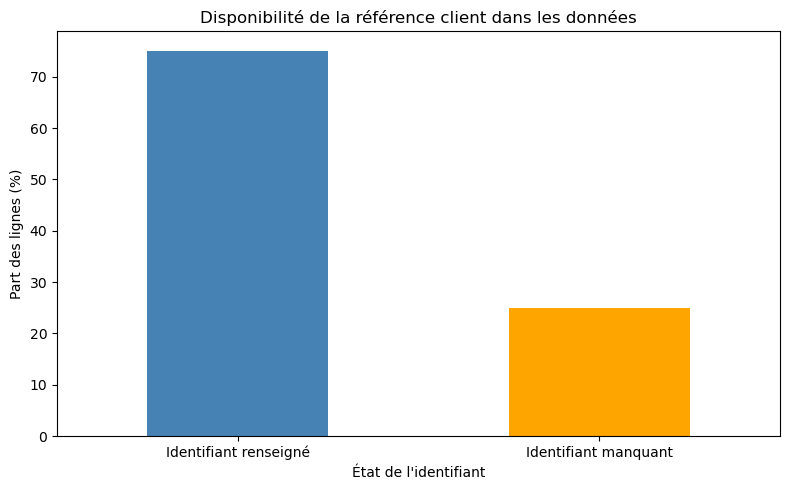

In [8]:
# Définir les deux catégories selon la disponibilité de CustomerID
statut_client = df["CustomerID"].notna().map({
    True: "Identifiant renseigné",
    False: "Identifiant manquant"
})

# Calculer le pourcentage de chaque catégorie
ordre_categories = [
    "Identifiant renseigné",
    "Identifiant manquant"
]

proportions = (
    statut_client.value_counts(normalize=True)
    .reindex(ordre_categories, fill_value=0)
    * 100
)

# Créer le graphique
proportions.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Disponibilité de la référence client dans les données")
plt.xlabel("État de l'identifiant")
plt.ylabel("Part des lignes (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Interprétation du graphique

La représentation compare la proportion des enregistrements pour lesquels CustomerID est disponible à celle des enregistrements où cette variable est vide. La catégorie dont la barre est la plus haute représente la situation la plus fréquente dans le fichier.

la barre des identifiants renseignés est supérieure à celle des identifiants manquants, on conclure que la majorité des lignes possède une référence client. 

## 5. Trace de faisabilité 

### Pour chaque question décisionnelle, quelles colonnes faut-il mobiliser et pour quelle raison ?

**Étude de l'évolution temporelle** : InvoiceDate, Quantity, UnitPrice, InvoiceNo. La date permet de regrouper les opérations par période, tandis que les quantités et les prix servent à construire un indicateur de montant. La référence de facture apporte un élément supplémentaire pour examiner les transactions.

**Classement des produits** : StockCode, Description, Quantity, UnitPrice. Les références et les libellés permettent de distinguer les articles. Les quantités servent à établir un classement par volume, et le prix unitaire peut être utilisé pour approfondir l'analyse commerciale.

**Comparaison entre pays** : Country, Quantity, UnitPrice, InvoiceNo. Ces variables permettent de répartir les opérations selon leur pays, de calculer des montants estimés et de compléter la comparaison par le nombre de factures.

**Analyse des factures et de l'identification client** : InvoiceNo, CustomerID, InvoiceDate. Ces champs permettent d'étudier les références de facture, d'examiner les dates des opérations et de mesurer la disponibilité de l'identifiant client.